# Stage 1 : Organizing Data from dataset:

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/private-dataset
/kaggle/input/private-dataset/SmokeRemovalDataset
/kaggle/input/private-dataset/SmokeRemovalDataset/valB
/kaggle/input/private-dataset/SmokeRemovalDataset/testB
/kaggle/input/private-dataset/SmokeRemovalDataset/valA
/kaggle/input/private-dataset/SmokeRemovalDataset/testA
/kaggle/input/private-dataset/SmokeRemovalDataset/trainB
/kaggle/input/private-dataset/SmokeRemovalDataset/trainA


In [2]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [3]:
import os
import shutil
from tqdm import tqdm

In [4]:
ROOT = "/kaggle/input/private-dataset/SmokeRemovalDataset"

OUTPUT = "/content/drive/MyDrive/Project 1/SmokeRemovalDataset"

In [5]:
train_cases = [
    "TLH_2",
    "TLH_6",
    "TLH_7",
    "TLH_8",
    "TLH_9",
    "TLH_10"
]

val_cases = [
    "TLH_11",
    "TLH_12"
]

test_cases = [
    "TLH_16",
    "TLH_17"
]

In [6]:
folders = [
    "trainA",
    "trainB",
    "valA",
    "valB",
    "testA",
    "testB"
]

for folder in folders:
    os.makedirs(os.path.join(OUTPUT, folder), exist_ok=True)

print("Folder structure created successfully!")

Folder structure created successfully!


In [7]:
def copy_images(case_list, output_folder, image_type):

    """
    image_type:
        hazy  -> Domain A
        clear -> Domain B
    """

    total = 0

    for case in case_list:

        src = os.path.join(ROOT, case, image_type)

        if not os.path.exists(src):
            print(f"Skipping {case} ({image_type})")
            continue

        images = sorted(os.listdir(src))

        for img in tqdm(images, desc=f"{case} ({image_type})"):

            src_path = os.path.join(src, img)

            # Prevent filename collisions
            new_name = f"{case}_{img}"

            dst_path = os.path.join(
                OUTPUT,
                output_folder,
                new_name
            )

            shutil.copy2(src_path, dst_path)

            total += 1

    print(f"\n{output_folder}: {total} images copied.")

In [8]:
# ----------------------------
# Training
# ----------------------------

copy_images(train_cases, "trainA", "hazy")
copy_images(train_cases, "trainB", "clear")

# ----------------------------
# Validation
# ----------------------------

copy_images(val_cases, "valA", "hazy")
copy_images(val_cases, "valB", "clear")

# ----------------------------
# Testing
# ----------------------------

copy_images(test_cases, "testA", "hazy")
copy_images(test_cases, "testB", "clear")

print("\nDataset organization completed!")

Skipping TLH_2 (hazy)
Skipping TLH_6 (hazy)
Skipping TLH_7 (hazy)
Skipping TLH_8 (hazy)
Skipping TLH_9 (hazy)
Skipping TLH_10 (hazy)

trainA: 0 images copied.
Skipping TLH_2 (clear)
Skipping TLH_6 (clear)
Skipping TLH_7 (clear)
Skipping TLH_8 (clear)
Skipping TLH_9 (clear)
Skipping TLH_10 (clear)

trainB: 0 images copied.
Skipping TLH_11 (hazy)
Skipping TLH_12 (hazy)

valA: 0 images copied.
Skipping TLH_11 (clear)
Skipping TLH_12 (clear)

valB: 0 images copied.
Skipping TLH_16 (hazy)
Skipping TLH_17 (hazy)

testA: 0 images copied.
Skipping TLH_16 (clear)
Skipping TLH_17 (clear)

testB: 0 images copied.

Dataset organization completed!


In [9]:
for folder in folders:

    n = len(os.listdir(os.path.join(OUTPUT, folder)))

    print(f"{folder:8s}: {n} images")

trainA  : 0 images
trainB  : 0 images
valA    : 0 images
valB    : 0 images
testA   : 0 images
testB   : 0 images


In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image

hazy_folder = os.path.join(OUTPUT, "trainA")
clear_folder = os.path.join(OUTPUT, "trainB")

hazy_img = random.choice(os.listdir(hazy_folder))
clear_img = random.choice(os.listdir(clear_folder))

hazy = Image.open(os.path.join(hazy_folder, hazy_img))
clear = Image.open(os.path.join(clear_folder, clear_img))

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(hazy)
plt.title("Random Smoky Image")


plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(clear)
plt.title("Random Clear Image")
plt.axis("off")

plt.show()

IndexError: Cannot choose from an empty sequence

# Stage 2: Data Loading & Preprocessing

In [11]:
import os
import random

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [12]:
DATASET_PATH = "/kaggle/input/private-dataset/SmokeRemovalDataset"

TRAIN_A = os.path.join(DATASET_PATH, "trainA")
TRAIN_B = os.path.join(DATASET_PATH, "trainB")

VAL_A = os.path.join(DATASET_PATH, "valA")
VAL_B = os.path.join(DATASET_PATH, "valB")

TEST_A = os.path.join(DATASET_PATH, "testA")
TEST_B = os.path.join(DATASET_PATH, "testB")

In [13]:
IMAGE_SIZE = 128

transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [14]:
class UnpairedSmokeDataset(Dataset):

    def __init__(self,
                 domainA_path,
                 domainB_path,
                 transform=None):

        self.domainA_path = domainA_path
        self.domainB_path = domainB_path

        self.domainA = sorted(os.listdir(domainA_path))
        self.domainB = sorted(os.listdir(domainB_path))

        self.transform = transform

    def __len__(self):

        return max(len(self.domainA), len(self.domainB))

    def __getitem__(self, index):

        imageA = self.domainA[index % len(self.domainA)]

        imageB = random.choice(self.domainB)

        pathA = os.path.join(self.domainA_path, imageA)
        pathB = os.path.join(self.domainB_path, imageB)

        imageA = Image.open(pathA).convert("RGB")
        imageB = Image.open(pathB).convert("RGB")

        if self.transform:

            imageA = self.transform(imageA)
            imageB = self.transform(imageB)

        return {

            "A": imageA,
            "B": imageB
        }

In [15]:
train_dataset = UnpairedSmokeDataset(

    TRAIN_A,

    TRAIN_B,

    transform=transform

)

In [16]:
val_dataset = UnpairedSmokeDataset(

    VAL_A,

    VAL_B,

    transform=transform

)

In [17]:
test_dataset = UnpairedSmokeDataset(

    TEST_A,

    TEST_B,

    transform=transform

)

In [18]:
BATCH_SIZE = 1

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

In [19]:
batch = next(iter(train_loader))

print(batch["A"].shape)
print(batch["B"].shape)

torch.Size([1, 3, 128, 128])
torch.Size([1, 3, 128, 128])


In [20]:
def denormalize(img):

    img = img * 0.5 + 0.5
    return img.clamp(0,1)

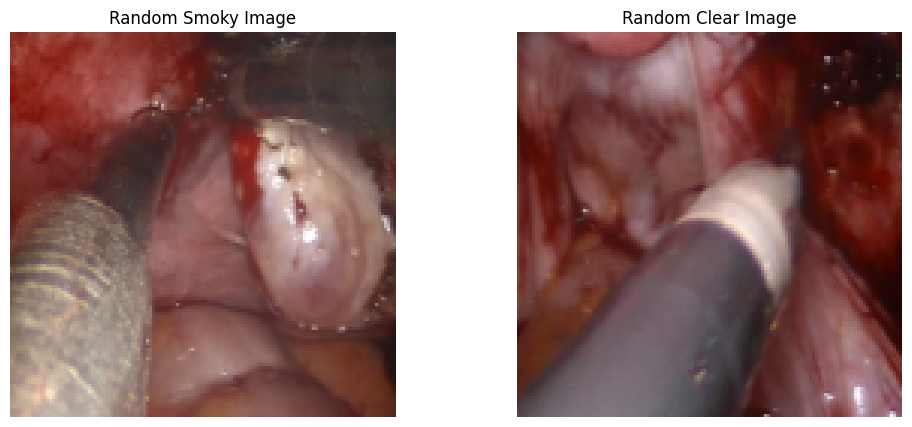

In [21]:
batch = next(iter(train_loader))

smoke = denormalize(batch["A"][0])
clear = denormalize(batch["B"][0])

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(smoke.permute(1,2,0))
plt.title("Random Smoky Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(clear.permute(1,2,0))
plt.title("Random Clear Image")
plt.axis("off")

plt.show()

# Stage 3: Adaptive Smoke Prior Estimation (ASPE)

In [22]:
import torch
import torch.nn as nn

In [23]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(x + self.block(x))

In [24]:
class AdaptiveSmokePriorEstimator(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.res1 = ResidualBlock(32)
        self.res2 = ResidualBlock(32)
        self.dilated = nn.Sequential(
            nn.Conv2d(
                32,
                32,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.output = nn.Sequential(
            nn.Conv2d(32, 1, kernel_size=1),
            nn.Sigmoid()
        )
    def forward(self, x):
        x = self.initial(x)
        x = self.res1(x)
        x = self.res2(x)
        x = self.dilated(x)
        smoke_map = self.output(x)
        return smoke_map

In [25]:
model = AdaptiveSmokePriorEstimator()
dummy = torch.randn(2, 3, 256, 256)
smoke_map = model(dummy)
print("Input Shape :", dummy.shape)
print("Smoke Map Shape :", smoke_map.shape)

Input Shape : torch.Size([2, 3, 256, 256])
Smoke Map Shape : torch.Size([2, 1, 256, 256])


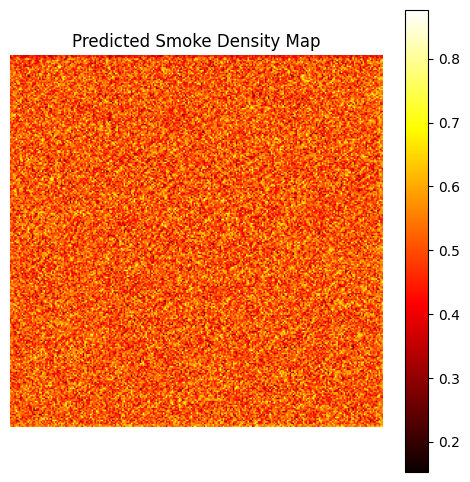

In [26]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(smoke_map[0,0].detach().numpy(), cmap="hot")
plt.title("Predicted Smoke Density Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 4 — Adaptive Multiscale Feature Encoder (AMFE)

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [28]:
class MultiScaleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv3 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.dilated = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        f3 = self.conv3(x)
        f5 = self.conv5(x)
        fd = self.dilated(x)
        return f3, f5, fd

In [29]:
class ScaleWeightPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.predictor = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(1,16,1),
            nn.ReLU(),
            nn.Conv2d(16,3,1),
            nn.Softmax(dim=1)
        )
    def forward(self, smoke_map):
        weights = self.predictor(smoke_map)
        return weights

In [30]:
class AdaptiveFeatureFusion(nn.Module):
    def forward(self, f3, f5, fd, weights):
        w1 = weights[:,0:1]
        w2 = weights[:,1:2]
        w3 = weights[:,2:3]
        fused = (
            w1*f3 +
            w2*f5 +
            w3*fd
        )
        return fused

In [31]:
class AdaptiveMultiscaleEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.multiscale = MultiScaleConv(
            in_channels=3,
            out_channels=64
        )
        self.weight_predictor = ScaleWeightPredictor()
        self.fusion = AdaptiveFeatureFusion()
    def forward(self, x, smoke_map):
        f3,f5,fd = self.multiscale(x)
        weights = self.weight_predictor(smoke_map)
        fused = self.fusion(
            f3,
            f5,
            fd,
            weights
        )
        return fused, weights

In [32]:
encoder = AdaptiveMultiscaleEncoder()
dummy = torch.randn(2,3,256,256)
smoke = torch.rand(2,1,256,256)
features, weights = encoder(dummy, smoke)
print(features.shape)
print(weights.shape)

torch.Size([2, 64, 256, 256])
torch.Size([2, 3, 1, 1])


In [33]:
weights = weights.squeeze(-1).squeeze(-1).detach().cpu()
for i in range(weights.shape[0]):
    print(f"Image {i+1}")
    print(f"3×3 Weight     : {weights[i,0]:.3f}")
    print(f"5×5 Weight     : {weights[i,1]:.3f}")
    print(f"Dilated Weight : {weights[i,2]:.3f}")
    print()

Image 1
3×3 Weight     : 0.497
5×5 Weight     : 0.260
Dilated Weight : 0.243

Image 2
3×3 Weight     : 0.497
5×5 Weight     : 0.260
Dilated Weight : 0.243



# Stage 5 – Frequency-Aware Feature Enhancement Module (FAFEM)

In [34]:
import torch
import torch.nn as nn

In [35]:
class FFTFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, x):
        # FFT
        fft = torch.fft.fft2(x)
        amplitude = torch.abs(fft)
        phase = torch.angle(fft)
        return amplitude, phase

In [36]:
class HighFrequencyEnhancer(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.enhance = nn.Sequential(
            nn.Conv2d(channels, channels, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 1),
            nn.Sigmoid()
        )
    def forward(self, amplitude):
        weight = self.enhance(amplitude)
        enhanced = amplitude * (1 + weight)
        return enhanced

In [37]:
class InverseFFT(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, amplitude, phase):
        real = amplitude * torch.cos(phase)
        imag = amplitude * torch.sin(phase)
        complex_fft = torch.complex(real, imag)
        feature = torch.fft.ifft2(complex_fft).real
        return feature

In [38]:
class FrequencyAwareFeatureEnhancement(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.fft = FFTFeatureExtractor()
        self.enhancer = HighFrequencyEnhancer(channels)
        self.ifft = InverseFFT()
    def forward(self, x):
        amplitude, phase = self.fft(x)
        enhanced_amplitude = self.enhancer(amplitude)
        output = self.ifft(enhanced_amplitude, phase)
        return output

In [39]:
freq_module = FrequencyAwareFeatureEnhancement(64)
dummy = torch.randn(2,64,256,256)
out = freq_module(dummy)
print(dummy.shape)
print(out.shape)

torch.Size([2, 64, 256, 256])
torch.Size([2, 64, 256, 256])


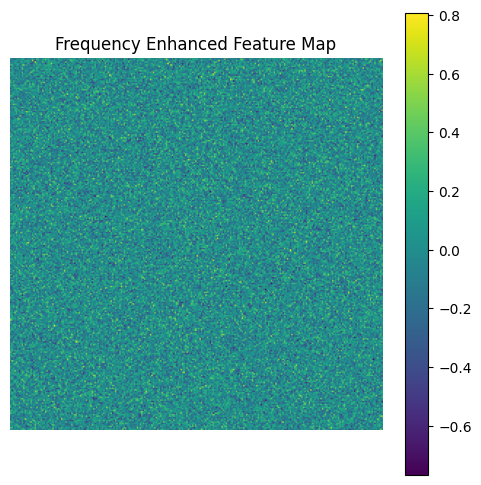

In [40]:
feature = out[0].mean(0).detach().cpu()
plt.figure(figsize=(6,6))
plt.imshow(feature, cmap="viridis")
plt.title("Frequency Enhanced Feature Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 6 — Cross-Domain Feature Fusion (CDFF)

In [41]:
import torch
import torch.nn as nn

In [42]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        weight = self.avg_pool(x)
        weight = self.fc(weight)
        return x * weight

In [43]:
class CrossDomainFusion(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.spatial_attention = ChannelAttention(channels)
        self.frequency_attention = ChannelAttention(channels)
        self.fusion = nn.Sequential(
            nn.Conv2d(channels * 2, channels, kernel_size=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, spatial, frequency):
        spatial = self.spatial_attention(spatial)
        frequency = self.frequency_attention(frequency)
        fused = torch.cat([spatial, frequency], dim=1)
        fused = self.fusion(fused)
        return fused

In [44]:
fusion = CrossDomainFusion(64)

spatial = torch.randn(2, 64, 256, 256)
frequency = torch.randn(2, 64, 256, 256)

output = fusion(spatial, frequency)

print("Spatial Feature Shape :", spatial.shape)
print("Frequency Feature Shape :", frequency.shape)
print("Fused Feature Shape :", output.shape)

Spatial Feature Shape : torch.Size([2, 64, 256, 256])
Frequency Feature Shape : torch.Size([2, 64, 256, 256])
Fused Feature Shape : torch.Size([2, 64, 256, 256])


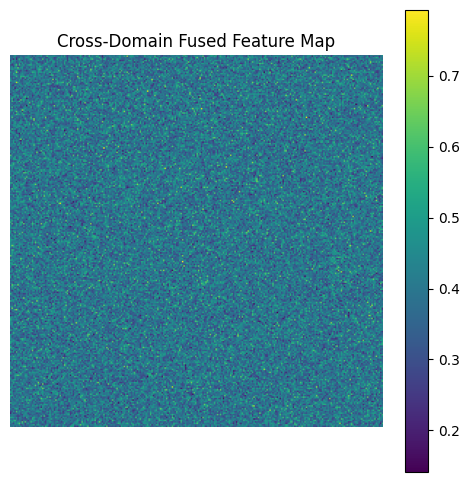

In [45]:
import matplotlib.pyplot as plt

feature = output[0].mean(dim=0).detach().cpu().numpy()

plt.figure(figsize=(6,6))
plt.imshow(feature, cmap="viridis")
plt.title("Cross-Domain Fused Feature Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 7 — Lightweight Global Context Transformer (LGCT)

In [46]:
import torch
import torch.nn as nn

def window_partition(x, window_size):
    B, C, H, W = x.shape
    x = x.view(B, C, H // window_size, window_size, W // window_size, window_size)
    x = x.permute(0, 2, 4, 3, 5, 1)
    windows = x.reshape(-1, window_size * window_size, C)
    return windows

In [47]:
def window_reverse(windows, window_size, H, W, B):
    C = windows.shape[-1]
    x = windows.view(B, H // window_size, W // window_size,
                     window_size, window_size, C)
    x = x.permute(0, 5, 1, 3, 2, 4)
    x = x.reshape(B, C, H, W)
    return x

In [48]:
class WindowAttention(nn.Module):
    def __init__(self, dim, num_heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):
        out, _ = self.attn(x, x, x)
        return out

In [49]:
class FeedForward(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        return self.net(x)

In [51]:
class WindowTransformerBlock(nn.Module):
    def __init__(self, dim=64, num_heads=4, window_size=8):
        super().__init__()
        self.window_size = window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = FeedForward(dim)

    def forward(self, x):
        B, C, H, W = x.shape
        windows = window_partition(x, self.window_size)
        shortcut = windows
        windows = self.norm1(windows)
        windows = shortcut + self.attn(windows)
        windows = windows + self.ffn(self.norm2(windows))
        x = window_reverse(
            windows,
            self.window_size,
            H,
            W,
            B
        )
        return x

In [52]:
class LightweightGlobalContextTransformer(nn.Module):
    def __init__(self,
                 channels=64,
                 num_heads=4,
                 window_size=8):

        super().__init__()
        self.block1 = WindowTransformerBlock(
            channels,
            num_heads,
            window_size
        )
        self.block2 = WindowTransformerBlock(
            channels,
            num_heads,
            window_size
        )
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return x

In [53]:
model = LightweightGlobalContextTransformer()
dummy = torch.randn(2,64,256,256)
output = model(dummy)
print(dummy.shape)
print(output.shape)

torch.Size([2, 64, 256, 256])
torch.Size([2, 64, 256, 256])


# Stage 8 — Edge-Guided Reconstruction Decoder (EGRD)

In [54]:
import torch
import torch.nn as nn

class EdgeAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.edge = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        edge_map = self.edge(x)
        return x * edge_map, edge_map

In [55]:
class ResidualRefinement(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(x + self.block(x))

In [56]:
class EdgeGuidedDecoder(nn.Module):
    def __init__(self, channels=64):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(channels, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.edge = EdgeAttention(64)
        self.refine1 = ResidualRefinement(64)
        self.refine2 = ResidualRefinement(64)
        self.output = nn.Sequential(
            nn.Conv2d(64, 3, 1),
            nn.Tanh()
        )
    def forward(self, x):
        x = self.conv1(x)
        x, edge_map = self.edge(x)
        x = self.refine1(x)
        x = self.refine2(x)
        output = self.output(x)
        return output, edge_map

In [57]:
decoder = EdgeGuidedDecoder()
dummy = torch.randn(2,64,256,256)
output, edge = decoder(dummy)
print(output.shape)
print(edge.shape)

torch.Size([2, 3, 256, 256])
torch.Size([2, 1, 256, 256])


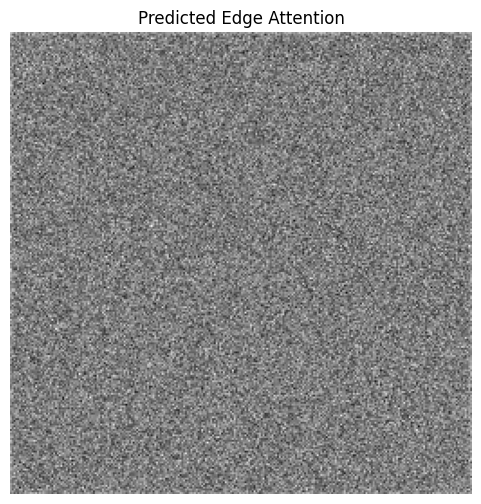

In [58]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(edge[0,0].detach().cpu(), cmap="gray")
plt.title("Predicted Edge Attention")
plt.axis("off")
plt.show()

# Stage 9 – Complete Generator Integration

In [59]:
class SmokeRemovalGenerator(nn.Module):
    def __init__(self):
        super().__init__()

        self.aspe = AdaptiveSmokePriorEstimator()

        self.encoder = AdaptiveMultiscaleEncoder()

        self.frequency = FrequencyAwareFeatureEnhancement(64)

        self.fusion = CrossDomainFusion(64)

        self.transformer = LightweightGlobalContextTransformer(
            channels=64,
            num_heads=4,
            window_size=8
        )

        self.decoder = EdgeGuidedDecoder(64)

    def forward(self, x):

        smoke_map = self.aspe(x)

        spatial_features, scale_weights = self.encoder(x, smoke_map)

        frequency_features = self.frequency(spatial_features)

        fused_features = self.fusion(
            spatial_features,
            frequency_features
        )

        transformer_features = self.transformer(fused_features)

        output, edge_map = self.decoder(transformer_features)

        return {
            "output": output,
            "smoke_map": smoke_map,
            "edge_map": edge_map,
            "scale_weights": scale_weights
        }

In [60]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator = SmokeRemovalGenerator().to(device)

print(generator)

SmokeRemovalGenerator(
  (aspe): AdaptiveSmokePriorEstimator(
    (initial): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (res1): ResidualBlock(
      (block): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (relu): ReLU(inplace=True)
    )
    (res2): ResidualBlock(
      (block): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     

In [61]:

dummy = torch.randn(2,3,256,256).to(device)

result = generator(dummy)

print("Output Image :", result["output"].shape)
print("Smoke Map :", result["smoke_map"].shape)
print("Edge Map :", result["edge_map"].shape)
print("Scale Weights :", result["scale_weights"].shape)
# print("Spatial Features :", result["spatial_features"].shape)
# print("Frequency Features :", result["frequency_features"].shape)
# print("Fused Features :", result["fused_features"].shape)

Output Image : torch.Size([2, 3, 256, 256])
Smoke Map : torch.Size([2, 1, 256, 256])
Edge Map : torch.Size([2, 1, 256, 256])
Scale Weights : torch.Size([2, 3, 1, 1])


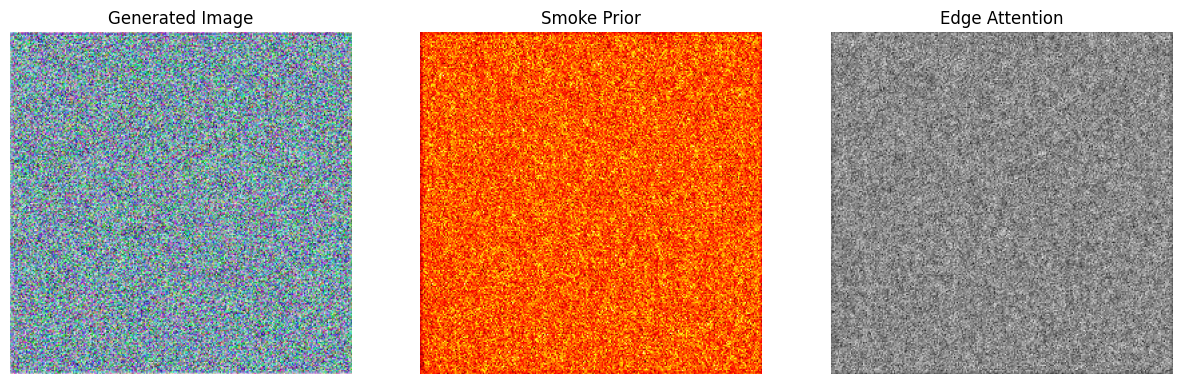

In [62]:
import matplotlib.pyplot as plt

sample = result

fig, ax = plt.subplots(1,3, figsize=(15,5))

output = sample["output"][0].detach().cpu()
output = output * 0.5 + 0.5

ax[0].imshow(output.permute(1,2,0))
ax[0].set_title("Generated Image")
ax[0].axis("off")

ax[1].imshow(sample["smoke_map"][0,0].detach().cpu(), cmap="hot")
ax[1].set_title("Smoke Prior")
ax[1].axis("off")

ax[2].imshow(sample["edge_map"][0,0].detach().cpu(), cmap="gray")
ax[2].set_title("Edge Attention")
ax[2].axis("off")

plt.show()

# Stage 10 – Dual PatchGAN Discriminators

In [63]:
import torch
import torch.nn as nn

class DiscriminatorBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=2):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, stride, 1),
            nn.InstanceNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [64]:
class PatchGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.block1 = DiscriminatorBlock(64, 128)
        self.block2 = DiscriminatorBlock(128, 256)
        self.block3 = DiscriminatorBlock(256, 512, stride=1)

        self.output = nn.Conv2d(
            512,
            1,
            kernel_size=4,
            stride=1,
            padding=1
        )

    def forward(self, x):
        x = self.initial(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.output(x)
        return x

In [65]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

D_smoke = PatchGANDiscriminator().to(device)

D_clear = PatchGANDiscriminator().to(device)

In [66]:
G_smoke_to_clear = SmokeRemovalGenerator().to(device)

G_clear_to_smoke = SmokeRemovalGenerator().to(device)

In [67]:
dummy = torch.randn(2,3,256,256).to(device)

out = D_clear(dummy)

print(out.shape)

torch.Size([2, 1, 30, 30])


In [68]:
smoke = torch.randn(2,3,256,256).to(device)

clear = torch.randn(2,3,256,256).to(device)

fake_clear = G_smoke_to_clear(smoke)["output"]

fake_smoke = G_clear_to_smoke(clear)["output"]

score_clear = D_clear(fake_clear)

score_smoke = D_smoke(fake_smoke)

print(fake_clear.shape)
print(fake_smoke.shape)

print(score_clear.shape)
print(score_smoke.shape)

torch.Size([2, 3, 256, 256])
torch.Size([2, 3, 256, 256])
torch.Size([2, 1, 30, 30])
torch.Size([2, 1, 30, 30])


# Stage 11 – Hybrid Multi-Objective Loss Function (HMOL)

In [69]:
import torch
import torch.nn as nn

adversarial_loss = nn.MSELoss()

In [70]:
cycle_loss = nn.L1Loss()

In [71]:
identity_loss = nn.L1Loss()

In [72]:
class FrequencyLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.L1Loss()

    def forward(self, pred, target):

        # Convert to float32 before FFT
        pred = pred.float()
        target = target.float()

        pred_fft = torch.abs(torch.fft.fft2(pred))
        target_fft = torch.abs(torch.fft.fft2(target))

        return self.l1(pred_fft, target_fft)

In [73]:
frequency_loss = FrequencyLoss()

In [74]:
class EdgeLoss(nn.Module):
    def __init__(self):
        super().__init__()

        self.l1 = nn.L1Loss()

        sobel_x = torch.tensor([
            [-1,0,1],
            [-2,0,2],
            [-1,0,1]
        ], dtype=torch.float32)

        sobel_y = torch.tensor([
            [-1,-2,-1],
            [0,0,0],
            [1,2,1]
        ], dtype=torch.float32)

        self.register_buffer(
            "sobel_x",
            sobel_x.view(1,1,3,3)
        )

        self.register_buffer(
            "sobel_y",
            sobel_y.view(1,1,3,3)
        )

    def gradient(self,x):

        gray = x.mean(dim=1,keepdim=True)

        sobel_x = self.sobel_x.to(gray.device)
        sobel_y = self.sobel_y.to(gray.device)

        gx = nn.functional.conv2d(
            gray,
            sobel_x,
            padding=1
        )

        gy = nn.functional.conv2d(
            gray,
            sobel_y,
            padding=1
        )

        return torch.sqrt(gx**2+gy**2+1e-6)

    def forward(self,pred,target):

        return self.l1(
            self.gradient(pred),
            self.gradient(target)
        )

In [75]:
edge_loss = EdgeLoss()

In [76]:
class SmokePriorLoss(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, smoke_map):
        dx = torch.abs(
            smoke_map[:,:,1:,:]-smoke_map[:,:,:-1,:]
        )
        dy = torch.abs(
            smoke_map[:,:,:,1:]-smoke_map[:,:,:,:-1]
        )
        return dx.mean()+dy.mean()

In [77]:
smoke_loss = SmokePriorLoss()

In [78]:
lambda_cycle = 10.0
lambda_identity = 5.0
lambda_frequency = 2.0
lambda_edge = 2.0
lambda_smoke = 0.1

In [79]:
def generator_loss(
    fake_score,
    fake_img,
    real_img,
    reconstructed_img,
    identity_img,
    smoke_map
):

    gan = adversarial_loss(
        fake_score,
        torch.ones_like(fake_score)
    )

    cycle = cycle_loss(
        reconstructed_img,
        real_img
    )

    identity = identity_loss(
        identity_img,
        real_img
    )

    freq = frequency_loss(
        fake_img,
        real_img
    )

    edge = edge_loss(
        fake_img,
        real_img
    )

    smoke = smoke_loss(
        smoke_map
    )

    total = (
        gan
        + lambda_cycle*cycle
        + lambda_identity*identity
        + lambda_frequency*freq
        + lambda_edge*edge
        + lambda_smoke*smoke
    )

    return total

# Stage 12 — Training Pipeline

In [80]:
import torch.optim as optim

lr = 2e-4
beta1 = 0.5
beta2 = 0.999

optimizer_G = optim.Adam(
    list(G_smoke_to_clear.parameters()) +
    list(G_clear_to_smoke.parameters()),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D_smoke = optim.Adam(
    D_smoke.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D_clear = optim.Adam(
    D_clear.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

In [81]:
scheduler_G = optim.lr_scheduler.StepLR(
    optimizer_G,
    step_size=50,
    gamma=0.5
)

scheduler_D_smoke = optim.lr_scheduler.StepLR(
    optimizer_D_smoke,
    step_size=50,
    gamma=0.5
)

scheduler_D_clear = optim.lr_scheduler.StepLR(
    optimizer_D_clear,
    step_size=50,
    gamma=0.5
)

In [82]:
def get_labels(prediction):
    real = torch.ones_like(prediction)
    fake = torch.zeros_like(prediction)
    return real, fake

In [83]:
from torch.amp import GradScaler, autocast
scaler = GradScaler("cuda")

def train_generator(smoke, clear):

    optimizer_G.zero_grad()
    with autocast(device_type="cuda"):
        fake_clear = G_smoke_to_clear(smoke)
        fake_smoke = G_clear_to_smoke(clear)

        reconstructed_smoke = G_clear_to_smoke(fake_clear["output"])
        reconstructed_clear = G_smoke_to_clear(fake_smoke["output"])

        identity_clear = G_smoke_to_clear(clear)
        identity_smoke = G_clear_to_smoke(smoke)

        score_clear = D_clear(fake_clear["output"])
        score_smoke = D_smoke(fake_smoke["output"])

        loss_clear = generator_loss(
            score_clear,
            fake_clear["output"],
            clear,
            reconstructed_clear["output"],
            identity_clear["output"],
            fake_clear["smoke_map"]
        )

        loss_smoke = generator_loss(
            score_smoke,
            fake_smoke["output"],
            smoke,
            reconstructed_smoke["output"],
            identity_smoke["output"],
            fake_smoke["smoke_map"]
        )

        loss = loss_clear + loss_smoke

    scaler.scale(loss).backward()
    scaler.step(optimizer_G)
    scaler.update()

    return loss.item()

In [84]:
!pip install -q scikit-learn

In [85]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [86]:
def train_discriminator(discriminator, optimizer, real, fake):
    optimizer.zero_grad()
    pred_real = discriminator(real)
    pred_fake = discriminator(fake.detach())
    real_label = torch.ones_like(pred_real)
    fake_label = torch.zeros_like(pred_fake)
    loss_real = adversarial_loss(pred_real, real_label)
    loss_fake = adversarial_loss(pred_fake, fake_label)
    loss = 0.5 * (loss_real + loss_fake)
    loss.backward()
    optimizer.step()
    real_true = torch.ones_like(pred_real).view(-1).cpu().numpy()
    fake_true = torch.zeros_like(pred_fake).view(-1).cpu().numpy()
    real_pred = (pred_real.detach().view(-1) >= 0.5).cpu().numpy().astype(int)
    fake_pred = (pred_fake.detach().view(-1) >= 0.5).cpu().numpy().astype(int)
    y_true = np.concatenate([real_true, fake_true]).astype(int)
    y_pred = np.concatenate([real_pred, fake_pred])
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    return loss.item(), metrics

In [87]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

edge_loss = EdgeLoss().to(device)
frequency_loss = FrequencyLoss().to(device)
smoke_loss = SmokePriorLoss().to(device)

In [88]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [89]:
history = {
    "G_loss": [],
    "D_loss": [],
    "D_accuracy": [],
    "D_precision": [],
    "D_recall": [],
    "D_f1": [],
    "lr": [],
    "epoch_time": []
}

from tqdm.auto import tqdm
import time
import torch

num_epochs = 50
start_training = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()
    G_loss_epoch = 0.0
    D_loss_epoch = 0.0
    accuracy_epoch = 0.0
    precision_epoch = 0.0
    recall_epoch = 0.0
    f1_epoch = 0.0

    progress_bar = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{num_epochs}",
        leave=False
    )

    for batch_idx, batch in progress_bar:
        smoke = batch["A"].to(device)
        clear = batch["B"].to(device)

        G_loss = train_generator(smoke, clear)

        fake_clear = G_smoke_to_clear(smoke)["output"]
        fake_smoke = G_clear_to_smoke(clear)["output"]

        D_clear_loss, D_clear_metrics = train_discriminator(
            D_clear,
            optimizer_D_clear,
            clear,
            fake_clear
        )

        D_smoke_loss, D_smoke_metrics = train_discriminator(
            D_smoke,
            optimizer_D_smoke,
            smoke,
            fake_smoke
        )

        D_loss = D_clear_loss + D_smoke_loss

        avg_accuracy = 0.5 * (
            D_clear_metrics["accuracy"] +
            D_smoke_metrics["accuracy"]
        )

        avg_precision = 0.5 * (
            D_clear_metrics["precision"] +
            D_smoke_metrics["precision"]
        )

        avg_recall = 0.5 * (
            D_clear_metrics["recall"] +
            D_smoke_metrics["recall"]
        )

        avg_f1 = 0.5 * (
            D_clear_metrics["f1"] +
            D_smoke_metrics["f1"]
        )

        G_loss_epoch += G_loss
        D_loss_epoch += D_loss
        accuracy_epoch += avg_accuracy
        precision_epoch += avg_precision
        recall_epoch += avg_recall
        f1_epoch += avg_f1

        progress_bar.set_postfix({
            "G": f"{G_loss:.3f}",
            "D": f"{D_loss:.3f}",
            "Acc": f"{avg_accuracy:.3f}",
            "Prec": f"{avg_precision:.3f}",
            "F1": f"{avg_f1:.3f}"
        })

    scheduler_G.step()
    scheduler_D_clear.step()
    scheduler_D_smoke.step()

    n = len(train_loader)

    G_avg = G_loss_epoch / n
    D_avg = D_loss_epoch / n
    acc_avg = accuracy_epoch / n
    prec_avg = precision_epoch / n
    recall_avg = recall_epoch / n
    f1_avg = f1_epoch / n

    epoch_time = time.time() - epoch_start

    history["G_loss"].append(G_avg)
    history["D_loss"].append(D_avg)
    history["D_accuracy"].append(acc_avg)
    history["D_precision"].append(prec_avg)
    history["D_recall"].append(recall_avg)
    history["D_f1"].append(f1_avg)
    history["lr"].append(optimizer_G.param_groups[0]["lr"])
    history["epoch_time"].append(epoch_time)

    print("\n" + "=" * 90)
    print(f"Epoch {epoch+1}/{num_epochs} Completed")
    print("=" * 90)
    print(f"Generator Loss       : {G_avg:.4f}")
    print(f"Discriminator Loss   : {D_avg:.4f}")
    print(f"Discriminator Accuracy: {acc_avg:.4f}")
    print(f"Discriminator Precision: {prec_avg:.4f}")
    print(f"Discriminator Recall : {recall_avg:.4f}")
    print(f"Discriminator F1     : {f1_avg:.4f}")
    print(f"Learning Rate        : {history['lr'][-1]:.7f}")
    print(f"Epoch Time           : {epoch_time:.2f} sec")
    print("=" * 90)

Epoch 1/50:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch 1/50 Completed
Generator Loss       : 36.3545
Discriminator Loss   : 0.3369
Discriminator Accuracy: 0.7829
Discriminator Precision: 0.8117
Discriminator Recall : 0.7548
Discriminator F1     : 0.7333
Learning Rate        : 0.0002000
Epoch Time           : 356.59 sec


Epoch 2/50:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch 2/50 Completed
Generator Loss       : 34.7250
Discriminator Loss   : 0.2723
Discriminator Accuracy: 0.8310
Discriminator Precision: 0.8478
Discriminator Recall : 0.8016
Discriminator F1     : 0.7814
Learning Rate        : 0.0002000
Epoch Time           : 357.39 sec


Epoch 3/50:   0%|          | 0/1800 [00:00<?, ?it/s]

...


Epoch 48/50 Completed
Generator Loss       : 28.6907
Discriminator Loss   : 0.0247
Discriminator Accuracy: 0.9935
Discriminator Precision: 0.9949
Discriminator Recall : 0.9946
Discriminator F1     : 0.9933
Learning Rate        : 0.0002000
Epoch Time           : 352.36 sec


Epoch 49/50:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch 49/50 Completed
Generator Loss       : 28.8637
Discriminator Loss   : 0.0255
Discriminator Accuracy: 0.9940
Discriminator Precision: 0.9951
Discriminator Recall : 0.9954
Discriminator F1     : 0.9942
Learning Rate        : 0.0002000
Epoch Time           : 352.51 sec


Epoch 50/50:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch 50/50 Completed
Generator Loss       : 28.9280
Discriminator Loss   : 0.0234
Discriminator Accuracy: 0.9939
Discriminator Precision: 0.9948
Discriminator Recall : 0.9949
Discriminator F1     : 0.9938
Learning Rate        : 0.0001000
Epoch Time           : 353.55 sec


In [90]:
import json
import numpy as np

# Convert any tensors/numpy values to normal Python floats
history_save = {}

for key, values in history.items():
    history_save[key] = [
        float(v.item()) if hasattr(v, "item") else float(v)
        for v in values
    ]

with open("training_history.json", "w") as f:
    json.dump(history_save, f, indent=4)

print("Training history saved successfully!")

Training history saved successfully!


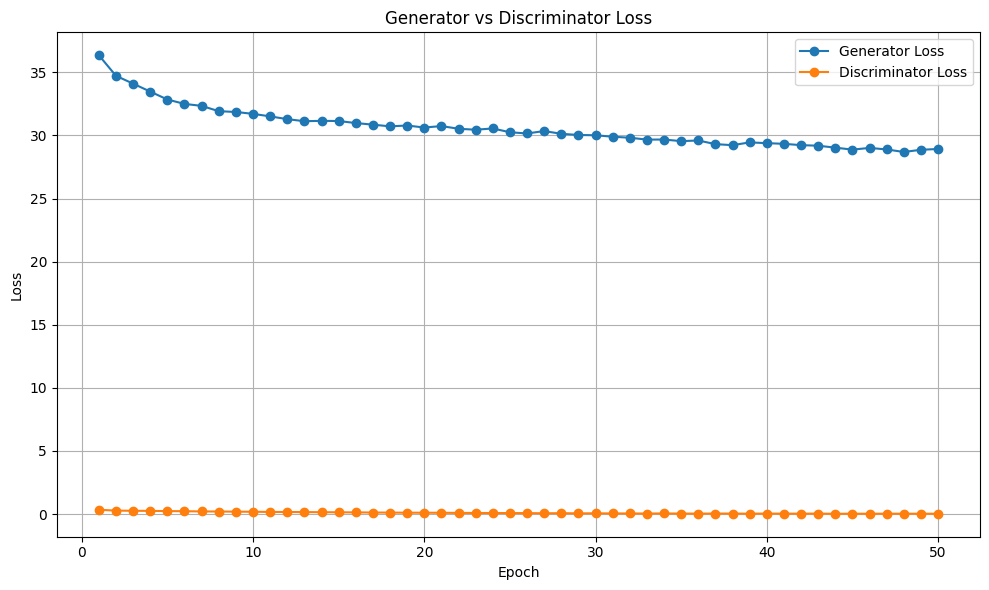

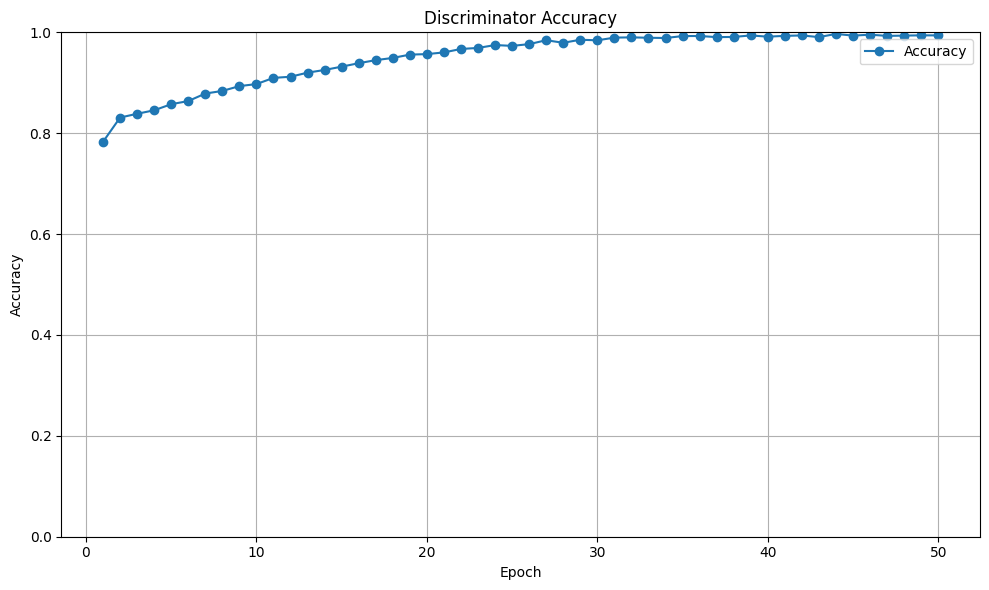

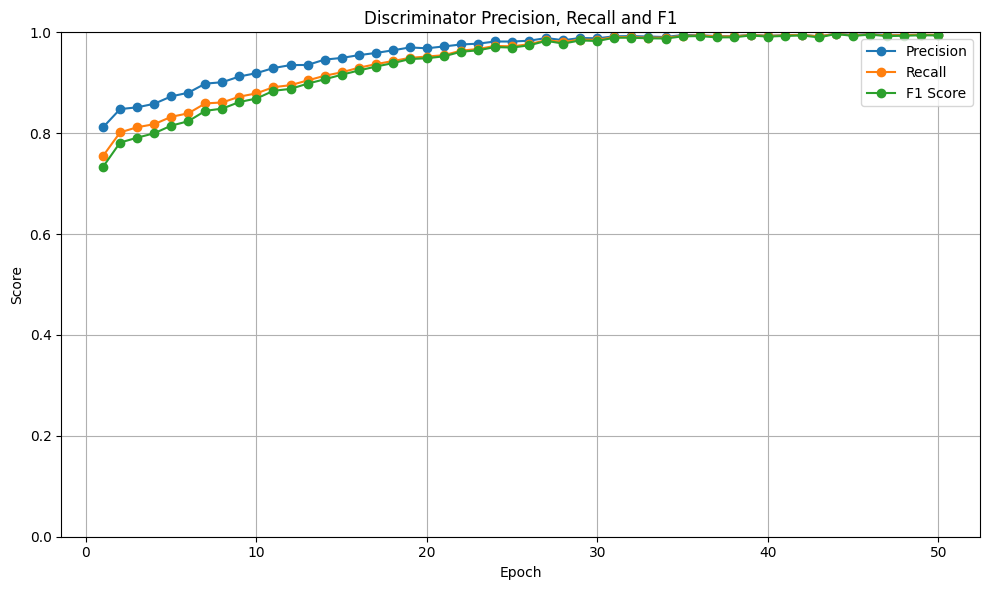

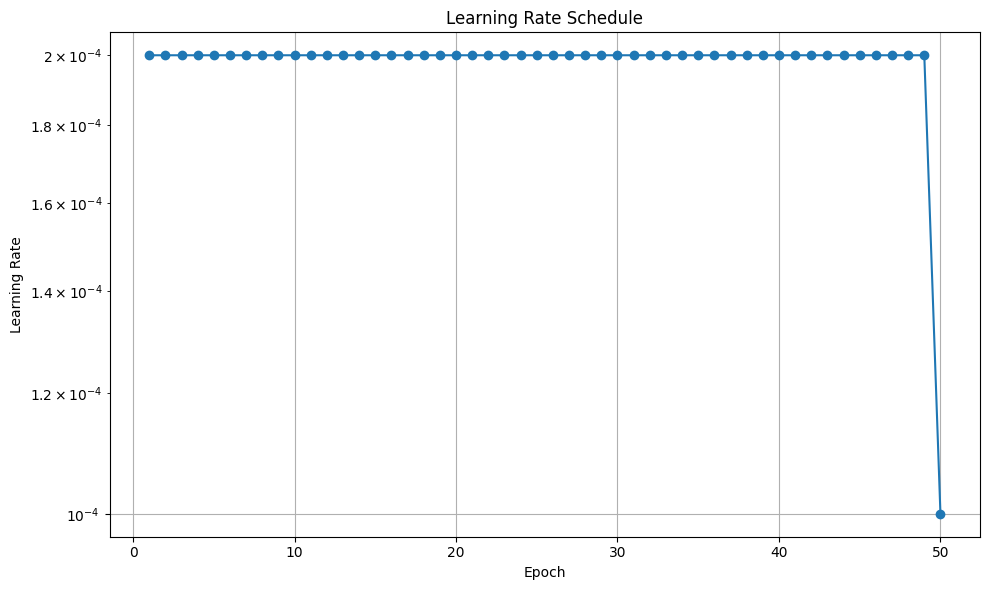

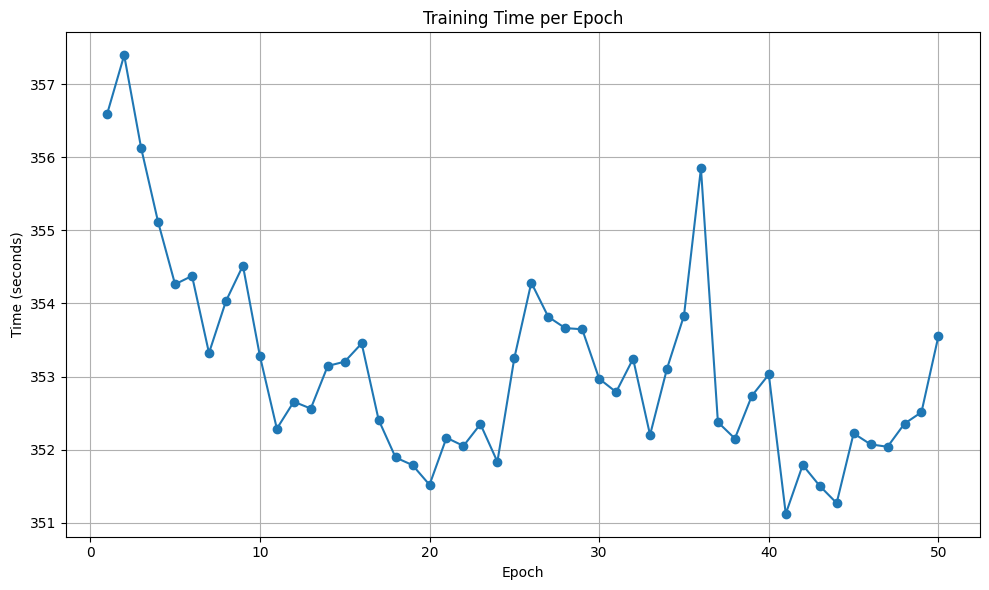

In [91]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history["G_loss"]) + 1)

# ============================================================
# 1. Generator and Discriminator Loss
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["G_loss"],
    marker="o",
    label="Generator Loss"
)

plt.plot(
    epochs,
    history["D_loss"],
    marker="o",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator vs Discriminator Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 2. Discriminator Accuracy
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["D_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Discriminator Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 3. Precision, Recall and F1
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["D_precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    epochs,
    history["D_recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    epochs,
    history["D_f1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Discriminator Precision, Recall and F1")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 4. Learning Rate
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["lr"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.yscale("log")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 5. Epoch Time
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["epoch_time"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Time (seconds)")
plt.title("Training Time per Epoch")
plt.grid(True)
plt.tight_layout()
plt.show()

In [92]:
import pandas as pd

metrics_df = pd.DataFrame({
    "Epoch": list(epochs),
    "Generator Loss": history["G_loss"],
    "Discriminator Loss": history["D_loss"],
    "Accuracy": history["D_accuracy"],
    "Precision": history["D_precision"],
    "Recall": history["D_recall"],
    "F1 Score": history["D_f1"],
    "Learning Rate": history["lr"],
    "Epoch Time (sec)": history["epoch_time"]
})

display(metrics_df)

,Epoch,Generator Loss,Discriminator Loss,Accuracy,Precision,Recall,F1 Score,Learning Rate,Epoch Time (sec)
0,1,36.354529,0.336893,0.782936,0.811660,0.754833,0.733340,0.0002,356.594396
1,2,34.724988,0.272256,0.831000,0.847842,0.801572,0.781421,0.0002,357.393031
2,3,34.104301,0.257279,0.838552,0.851292,0.811820,0.791132,0.0002,356.125012
3,4,33.474235,0.249748,0.845449,0.858327,0.817887,0.799854,0.0002,355.113187
4,5,32.848418,0.231197,0.857535,0.873022,0.832510,0.814995,0.0002,354.261611
5,6,32.499838,0.223451,0.863741,0.880239,0.839422,0.823751,0.0002,354.375794
6,7,32.343751,0.204579,0.878649,0.898299,0.859109,0.844331,0.0002,353.321860
7,8,31.922725,0.199844,0.883822,0.901126,0.860974,0.848811,0.0002,354.031070
8,9,31.860306,0.187277,0.893382,0.912442,0.872443,0.861864,0.0002,354.516712
9,10,31.710822,0.180504,0.897436,0.919118,0.879031,0.868751,0.0002,353.282002


In [93]:
metrics_df.to_csv(
    "training_metrics.csv",
    index=False
)

print("Saved: training_metrics.csv")

Saved: training_metrics.csv


In [94]:
print("=" * 70)
print("FINAL TRAINING RESULTS")
print("=" * 70)

print(f"Final Generator Loss       : {history['G_loss'][-1]:.4f}")
print(f"Final Discriminator Loss   : {history['D_loss'][-1]:.4f}")
print(f"Final Discriminator Accuracy: {history['D_accuracy'][-1]:.4f}")
print(f"Final Discriminator Precision: {history['D_precision'][-1]:.4f}")
print(f"Final Discriminator Recall : {history['D_recall'][-1]:.4f}")
print(f"Final Discriminator F1     : {history['D_f1'][-1]:.4f}")
print(f"Final Learning Rate        : {history['lr'][-1]:.7f}")

total_time = sum(history["epoch_time"])

print(f"Total Training Time        : {total_time:.2f} sec")
print(f"Total Training Time        : {total_time/60:.2f} min")

print("=" * 70)

FINAL TRAINING RESULTS
Final Generator Loss       : 28.9280
Final Discriminator Loss   : 0.0234
Final Discriminator Accuracy: 0.9939
Final Discriminator Precision: 0.9948
Final Discriminator Recall : 0.9949
Final Discriminator F1     : 0.9938
Final Learning Rate        : 0.0001000
Total Training Time        : 17655.72 sec
Total Training Time        : 294.26 min


In [95]:
best_f1_idx = np.argmax(history["D_f1"])

print("Best F1 Epoch:", best_f1_idx + 1)
print("Best F1:", history["D_f1"][best_f1_idx])

Best F1 Epoch: 44
Best F1: 0.9967794597271097


In [96]:
best_acc_idx = np.argmax(history["D_accuracy"])

print("Best Accuracy Epoch:", best_acc_idx + 1)
print("Best Accuracy:", history["D_accuracy"][best_acc_idx])

Best Accuracy Epoch: 44
Best Accuracy: 0.9968891723356


In [97]:
best_g_idx = np.argmin(history["G_loss"])

print("Lowest Generator Loss Epoch:", best_g_idx + 1)
print("Lowest Generator Loss:", history["G_loss"][best_g_idx])

Lowest Generator Loss Epoch: 48
Lowest Generator Loss: 28.69067719883389


In [98]:
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

import torch
import numpy as np

G_smoke_to_clear.eval()

total_mse = 0.0
total_mae = 0.0
total_psnr = 0.0
total_ssim = 0.0

num_images = 0

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Evaluating"):

        smoke = batch["A"].to(device)
        real_clear = batch["B"].to(device)

        fake_clear = G_smoke_to_clear(smoke)["output"]

        fake_clear = torch.clamp(fake_clear, 0, 1)
        real_clear = torch.clamp(real_clear, 0, 1)

        batch_size = smoke.size(0)

        for i in range(batch_size):

            generated = fake_clear[i].detach().cpu().numpy()
            target = real_clear[i].detach().cpu().numpy()

            # CHW → HWC
            generated = np.transpose(generated, (1, 2, 0))
            target = np.transpose(target, (1, 2, 0))

            mse = np.mean((generated - target) ** 2)
            mae = np.mean(np.abs(generated - target))

            psnr = peak_signal_noise_ratio(
                target,
                generated,
                data_range=1.0
            )

            ssim = structural_similarity(
                target,
                generated,
                channel_axis=2,
                data_range=1.0
            )

            total_mse += mse
            total_mae += mae
            total_psnr += psnr
            total_ssim += ssim

            num_images += 1


mse_avg = total_mse / num_images
mae_avg = total_mae / num_images
psnr_avg = total_psnr / num_images
ssim_avg = total_ssim / num_images

print("=" * 60)
print("IMAGE TRANSLATION METRICS")
print("=" * 60)

print(f"MSE  : {mse_avg:.6f}")
print(f"MAE  : {mae_avg:.6f}")
print(f"PSNR : {psnr_avg:.4f} dB")
print(f"SSIM : {ssim_avg:.4f}")

print("=" * 60)

Evaluating:   0%|          | 0/600 [00:00<?, ?it/s]

IMAGE TRANSLATION METRICS
MSE  : 0.069391
MAE  : 0.134891
PSNR : 12.3621 dB
SSIM : 0.4545


In [99]:
torch.save(
    G_smoke_to_clear.state_dict(),
    "G_smoke_to_clear_final.pth"
)

torch.save(
    G_clear_to_smoke.state_dict(),
    "G_clear_to_smoke_final.pth"
)

torch.save(
    D_clear.state_dict(),
    "D_clear_final.pth"
)

torch.save(
    D_smoke.state_dict(),
    "D_smoke_final.pth"
)

print("All models saved successfully!")

All models saved successfully!


In [100]:
torch.save({
    "epoch": num_epochs,
    "G_smoke_to_clear": G_smoke_to_clear.state_dict(),
    "G_clear_to_smoke": G_clear_to_smoke.state_dict(),
    "D_clear": D_clear.state_dict(),
    "D_smoke": D_smoke.state_dict(),
    "optimizer_G": optimizer_G.state_dict(),
    "optimizer_D_clear": optimizer_D_clear.state_dict(),
    "optimizer_D_smoke": optimizer_D_smoke.state_dict(),
    "history": history
}, "final_checkpoint.pth")

print("Complete checkpoint saved!")

Complete checkpoint saved!


In [101]:
import os
import torch

SAVE_DIR = "/kaggle/working/models"
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save(
    G_smoke_to_clear.state_dict(),
    os.path.join(SAVE_DIR, "SmokeRemovalGenerator.pth")
)

print("Model saved successfully!")

Model saved successfully!


In [102]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SmokeRemovalGenerator().to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/models/SmokeRemovalGenerator.pth",
        map_location=device
        
    )
)

model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [103]:
OUTPUT_DIR = "/kaggle/working/TestResults"

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [104]:
import torchvision.utils as vutils

model.eval()

with torch.no_grad():

    for idx, batch in enumerate(test_loader):

        smoke = batch["A"].to(device)

        output = model(smoke)["output"]

        output = (output * 0.5 + 0.5).clamp(0,1)

        smoke = (smoke * 0.5 + 0.5).clamp(0,1)

        vutils.save_image(
            output,
            os.path.join(
                OUTPUT_DIR,
                f"output_{idx:04d}.png"
            )
        )

print("Testing completed.")

Testing completed.


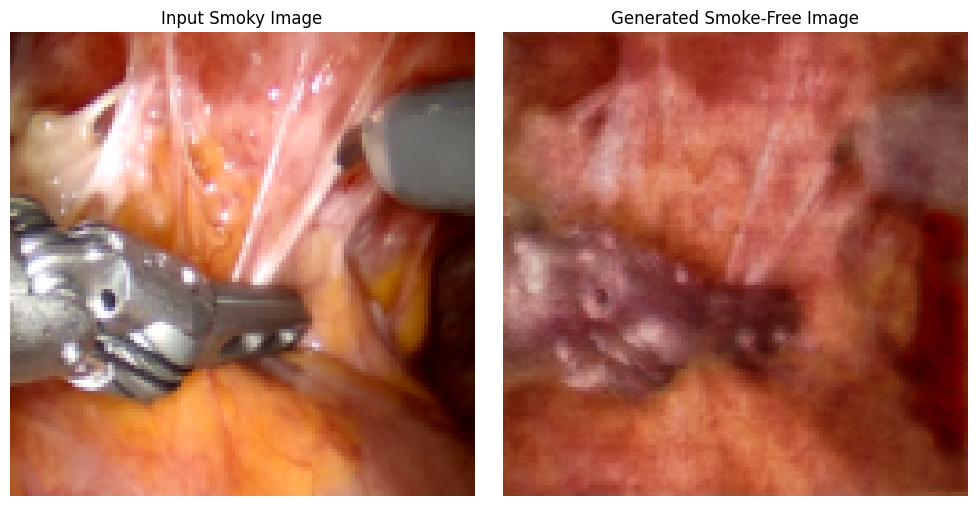

In [105]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():

    batch = next(iter(test_loader))

    smoke = batch["A"].to(device)

    output = model(smoke)["output"]

smoke = (smoke.cpu() * 0.5 + 0.5).clamp(0,1)
output = (output.cpu() * 0.5 + 0.5).clamp(0,1)

num_images = min(5, smoke.size(0))

fig, axes = plt.subplots(num_images, 2, figsize=(10, 5 * num_images))

# Fix when batch size = 1
if num_images == 1:
    axes = axes.reshape(1, 2)

for i in range(num_images):

    axes[i,0].imshow(smoke[i].permute(1,2,0))
    axes[i,0].set_title("Input Smoky Image")
    axes[i,0].axis("off")

    axes[i,1].imshow(output[i].permute(1,2,0))
    axes[i,1].set_title("Generated Smoke-Free Image")
    axes[i,1].axis("off")

plt.tight_layout()
plt.show()

In [106]:
import torchvision.utils as vutils

COMPARE_DIR = "/kaggle/working/Comparisons"

os.makedirs(COMPARE_DIR, exist_ok=True)

model.eval()

with torch.no_grad():

    for idx, batch in enumerate(test_loader):

        smoke = batch["A"].to(device)

        output = model(smoke)["output"]

        smoke = smoke.cpu()*0.5 + 0.5
        output = output.cpu()*0.5 + 0.5

        comparison = torch.cat(
            [
                smoke,
                output.cpu()
            ],
            dim=3
        )

        vutils.save_image(
            comparison,
            os.path.join(
                COMPARE_DIR,
                f"comparison_{idx:04d}.png"
            )
        )

print("Comparison images saved.")

Comparison images saved.


In [107]:
from IPython.display import display
import ipywidgets as widgets

uploader = widgets.FileUpload(
    accept='image/*',
    multiple=False
)

display(uploader)

FileUpload(value=(), accept='image/*', description='Upload')

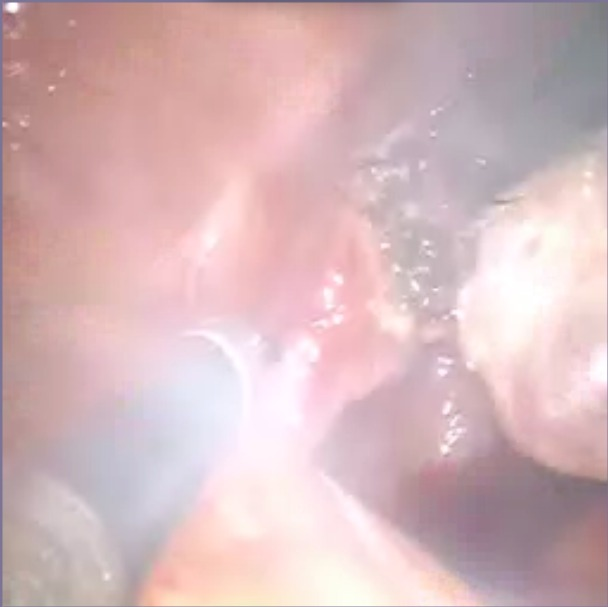

In [108]:
from PIL import Image
import io

uploaded_file = uploader.value[0]

image = Image.open(
    io.BytesIO(uploaded_file.content)
).convert("RGB")

image

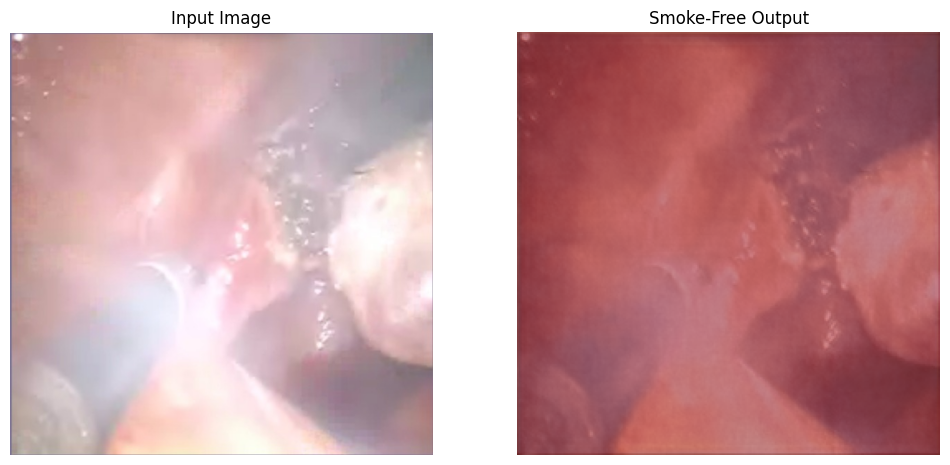

In [109]:
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

model.eval()

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Convert uploaded image to tensor
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    result = model(input_tensor)

# Your generator returns a dictionary
output = result["output"]

# Convert back to image
output = output.squeeze(0).cpu()
output = output * 0.5 + 0.5
output = output.clamp(0, 1)

# Display
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image)
ax[0].set_title("Input Image")
ax[0].axis("off")

ax[1].imshow(output.permute(1, 2, 0))
ax[1].set_title("Smoke-Free Output")
ax[1].axis("off")

plt.show()

In [110]:
!pip install -q pyiqa fade-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 16.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 94.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 100.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 81.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 108.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 563.0/563.0 kB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 18.0 MB/s eta 0:00:00
   ━

In [111]:
import os
import torch
from torchvision.utils import save_image
from tqdm.auto import tqdm

# Create directories
os.makedirs("evaluation/real_clear", exist_ok=True)
os.makedirs("evaluation/generated_clear", exist_ok=True)

G_smoke_to_clear.eval()

image_counter = 0

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Generating test images"):

        smoke = batch["A"].to(device)
        real_clear = batch["B"].to(device)

        # Generate clear image
        fake_clear = G_smoke_to_clear(smoke)["output"]

        # ------------------------------------------------
        # IMPORTANT:
        # Change this depending on your generator output.
        # ------------------------------------------------

        # If generator output is [-1, 1]:
        fake_clear = (fake_clear + 1) / 2
        real_clear = (real_clear + 1) / 2

        fake_clear = torch.clamp(fake_clear, 0, 1)
        real_clear = torch.clamp(real_clear, 0, 1)

        for i in range(smoke.size(0)):

            save_image(
                fake_clear[i],
                f"evaluation/generated_clear/{image_counter:06d}.png"
            )

            save_image(
                real_clear[i],
                f"evaluation/real_clear/{image_counter:06d}.png"
            )

            image_counter += 1

print(f"\nSaved {image_counter} image pairs.")

Generating test images:   0%|          | 0/600 [00:00<?, ?it/s]


Saved 600 image pairs.


# Calculate PIQE

In [112]:
import pyiqa
import torch
from PIL import Image
import torchvision.transforms as transforms
from pathlib import Path
from tqdm.auto import tqdm

device_iqa = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

piqe_metric = pyiqa.create_metric(
    "piqe",
    device=device_iqa
)

transform = transforms.ToTensor()

generated_dir = Path("evaluation/generated_clear")

piqe_scores = []

for img_path in tqdm(
    sorted(generated_dir.glob("*.png")),
    desc="Calculating PIQE"
):

    img = Image.open(img_path).convert("RGB")
    img = transform(img).unsqueeze(0).to(device_iqa)

    with torch.no_grad():
        score = piqe_metric(img)

    piqe_scores.append(score.item())

piqe_mean = sum(piqe_scores) / len(piqe_scores)

print("=" * 60)
print(f"PIQE Score: {piqe_mean:.4f}")
print("=" * 60)

Calculating PIQE:   0%|          | 0/600 [00:00<?, ?it/s]

PIQE Score: 13.0366


# Calculate FADE

In [113]:
!pip install -U fade-python

In [114]:
import pyfade

print(dir(pyfade))

['FolderResult', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '__version__', '_compat', 'core', 'fade', 'fade_array', 'fade_folder', 'fade_image', 'load_image']


In [115]:
# ============================================================
# FINAL FADE SCORE
# ============================================================

import pyfade
import numpy as np

generated_dir = "evaluation/generated_clear"

# Calculate FADE
result = pyfade.fade(
    generated_dir,
    progress=True
)

# Extract image-wise FADE scores
fade_scores = list(result.__dict__["scores"].values())

# Calculate mean
fade_score = np.mean(fade_scores)

print("=" * 60)
print("FADE EVALUATION")
print("=" * 60)
print(f"Images evaluated : {len(fade_scores)}")
print(f"Mean FADE Score  : {fade_score:.6f}")
print(f"Min FADE Score   : {np.min(fade_scores):.6f}")
print(f"Max FADE Score   : {np.max(fade_scores):.6f}")
print(f"Std FADE Score   : {np.std(fade_scores):.6f}")
print("=" * 60)

print("Lower FADE = less perceptual haze/fog")

pyfade:   0%|          | 0/600 [00:00<?, ?it/s]

FADE EVALUATION
Images evaluated : 600
Mean FADE Score  : 0.362585
Min FADE Score   : 0.202419
Max FADE Score   : 0.703495
Std FADE Score   : 0.087307
Lower FADE = less perceptual haze/fog


In [116]:
import pandas as pd

fade_df = pd.DataFrame({
    "Image": list(result.__dict__["scores"].keys()),
    "FADE": list(result.__dict__["scores"].values())
})

fade_df.to_csv("fade_scores.csv", index=False)

print("Saved: fade_scores.csv")

Saved: fade_scores.csv


# Calculate FID

In [117]:
import pyiqa
import torch

fid_metric = pyiqa.create_metric(
    "fid",
    device=device_iqa
)

fid_score = fid_metric(
    "evaluation/generated_clear",
    "evaluation/real_clear"
)

print("=" * 60)
print(f"FID Score: {fid_score.item():.4f}")
print("=" * 60)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/pyiqa/pt_inception-2015-12-05-6726825d.pth



100%|██████████| 91.2M/91.2M [00:01<00:00, 68.5MB/s]


Loading pretrained model Inception3 from /root/.cache/torch/hub/pyiqa/pt_inception-2015-12-05-6726825d.pth
Computing FID between two folders
Found 600 images in the folder evaluation/generated_clear


FID generated_clear: 100%|██████████| 75/75 [00:03<00:00, 19.53it/s]


Found 600 images in the folder evaluation/real_clear


FID real_clear: 100%|██████████| 75/75 [00:03<00:00, 20.51it/s]


FID Score: 244.5918


# Calculate KID

In [118]:
# ============================================================
# KID - STANDALONE IMPLEMENTATION
# Does NOT require torchmetrics or torch-fidelity
# ============================================================

import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision import models, transforms

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

REAL_DIR = Path("evaluation/real_clear")
FAKE_DIR = Path("evaluation/generated_clear")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ------------------------------------------------------------
# LOAD INCEPTION-V3
# ------------------------------------------------------------

print("Loading Inception-v3...")

weights = models.Inception_V3_Weights.DEFAULT
inception = models.inception_v3(weights=weights)

# Remove final classification layer
inception.fc = nn.Identity()

inception = inception.to(device)
inception.eval()

# Official preprocessing for Inception-v3
preprocess = weights.transforms()


# ------------------------------------------------------------
# EXTRACT INCEPTION FEATURES
# ------------------------------------------------------------

def extract_features(folder, batch_size=16):

    paths = sorted(folder.glob("*.png"))

    features = []

    for start in tqdm(
        range(0, len(paths), batch_size),
        desc=f"Extracting {folder.name}"
    ):

        batch_paths = paths[start:start + batch_size]

        images = []

        for path in batch_paths:

            img = Image.open(path).convert("RGB")

            img = preprocess(img)

            images.append(img)

        images = torch.stack(images).to(device)

        with torch.no_grad():

            feat = inception(images)

            # Flatten if necessary
            feat = feat.view(feat.size(0), -1)

        features.append(feat.cpu())

    return torch.cat(features, dim=0).numpy()


# ------------------------------------------------------------
# EXTRACT FEATURES
# ------------------------------------------------------------

real_features = extract_features(REAL_DIR)

fake_features = extract_features(FAKE_DIR)

print("\nFeature extraction complete.")

print("Real features :", real_features.shape)
print("Fake features :", fake_features.shape)


# ------------------------------------------------------------
# KID CALCULATION
# ------------------------------------------------------------

def polynomial_kernel(X, Y):

    degree = 3
    gamma = 1.0 / X.shape[1]
    coef = 1.0

    return (
        gamma * np.dot(X, Y.T) + coef
    ) ** degree


def calculate_kid(
    real_features,
    fake_features,
    subset_size=100,
    subsets=10
):

    n_real = len(real_features)
    n_fake = len(fake_features)

    subset_size = min(
        subset_size,
        n_real,
        n_fake
    )

    scores = []

    rng = np.random.default_rng(42)

    for _ in range(subsets):

        # Random subsets
        real_idx = rng.choice(
            n_real,
            subset_size,
            replace=False
        )

        fake_idx = rng.choice(
            n_fake,
            subset_size,
            replace=False
        )

        X = real_features[real_idx]
        Y = fake_features[fake_idx]

        # Kernel matrices
        K_XX = polynomial_kernel(X, X)
        K_YY = polynomial_kernel(Y, Y)
        K_XY = polynomial_kernel(X, Y)

        # Remove diagonal for unbiased MMD
        np.fill_diagonal(K_XX, 0)
        np.fill_diagonal(K_YY, 0)

        m = subset_size

        term_xx = K_XX.sum() / (m * (m - 1))
        term_yy = K_YY.sum() / (m * (m - 1))
        term_xy = K_XY.mean()

        kid = term_xx + term_yy - 2 * term_xy

        scores.append(kid)

    scores = np.array(scores)

    return scores.mean(), scores.std()


# ------------------------------------------------------------
# CALCULATE FINAL KID
# ------------------------------------------------------------

kid_mean, kid_std = calculate_kid(
    real_features,
    fake_features,
    subset_size=100,
    subsets=10
)


# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL KID RESULTS")
print("=" * 65)

print(f"Real images      : {len(real_features)}")
print(f"Generated images : {len(fake_features)}")
print(f"Subset size      : 100")
print(f"Number subsets   : 10")
print(f"KID Mean         : {kid_mean:.8f}")
print(f"KID Std          : {kid_std:.8f}")

print("=" * 65)
print("Lower KID = better")
print("=" * 65)

Device: cuda
Loading Inception-v3...
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 206MB/s] 


Extracting real_clear:   0%|          | 0/38 [00:00<?, ?it/s]

Extracting generated_clear:   0%|          | 0/38 [00:00<?, ?it/s]


Feature extraction complete.
Real features : (600, 2048)
Fake features : (600, 2048)

FINAL KID RESULTS
Real images      : 600
Generated images : 600
Subset size      : 100
Number subsets   : 10
KID Mean         : 0.17069976
KID Std          : 0.00818569
Lower KID = better
